# 🇯🇵 Nhận diện chữ Kanji - ResNet18 (Custom Implementation)

Notebook này thực hiện phân loại 100 lớp ký tự Kanji sử dụng mô hình ResNet18 tự implement bằng Keras (KHÔNG dùng pretrained).

**Nội dung:**
1. Mount Google Drive & Load dataset
2. Trực quan hóa dataset
3. Xây dựng mô hình ResNet18
4. Training
5. Phân tích kết quả
6. Lưu model

## 1. Cài đặt font CJK & Import thư viện

In [1]:
# ==================== CÀI ĐẶT FONT TIẾNG NHẬT ====================
!pip install -q japanize-matplotlib
!apt-get -y -qq install fonts-noto-cjk > /dev/null 2>&1

import japanize_matplotlib
import matplotlib
matplotlib.rcParams['axes.unicode_minus'] = False
print('✅ Font Nhật đã cài đặt và cấu hình xong')

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 62.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
✅ Font Nhật đã cài đặt và cấu hình xong


In [2]:
import os
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from PIL import Image

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Cấu hình & Hằng số

In [4]:
DATASET_DIR = '/content/drive/MyDrive/dataset/100class'
SAVE_DIR = '/content/drive/MyDrive/dataset'

IMG_SIZE = 64
IMG_SHAPE = (IMG_SIZE, IMG_SIZE, 3)  # ResNet cần 3 channels
NUM_CLASSES = 100
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 1e-3
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("✅ Cấu hình hoàn tất")
print(f"   Dataset: {DATASET_DIR}")
print(f"   Image size: {IMG_SIZE}x{IMG_SIZE}")
print(f"   Input shape: {IMG_SHAPE}")
print(f"   Num classes: {NUM_CLASSES}")
print(f"   Batch size: {BATCH_SIZE}")
print(f"   Epochs: {EPOCHS}")

✅ Cấu hình hoàn tất
   Dataset: /content/drive/MyDrive/dataset/100class
   Image size: 64x64
   Input shape: (64, 64, 3)
   Num classes: 100
   Batch size: 32
   Epochs: 50


## 4. Load Dataset

In [5]:
def load_dataset(dataset_dir, img_size):
    """Load ảnh grayscale, lặp thành 3 channels cho ResNet."""
    images = []
    labels = []
    class_names = sorted(os.listdir(dataset_dir))
    class_names = [c for c in class_names
                   if os.path.isdir(os.path.join(dataset_dir, c))]

    print(f"📂 Tìm thấy {len(class_names)} classes")

    for label_idx, class_name in enumerate(class_names):
        class_dir = os.path.join(dataset_dir, class_name)
        img_files = [f for f in os.listdir(class_dir)
                     if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        for img_file in img_files:
            img_path = os.path.join(class_dir, img_file)
            try:
                img = Image.open(img_path).convert('L')
                img = img.resize((img_size, img_size))
                img_array = np.array(img, dtype=np.float32) / 255.0
                img_array = np.stack([img_array] * 3, axis=-1)
                images.append(img_array)
                labels.append(label_idx)
            except Exception as e:
                print(f"   ⚠️ Lỗi: {img_path}: {e}")

    images = np.array(images)
    labels = np.array(labels)
    print(f"✅ Load xong: {len(images)} ảnh, {len(class_names)} classes")
    return images, labels, class_names


images, labels, class_names = load_dataset(DATASET_DIR, IMG_SIZE)
print(f"\n📊 Thông tin dataset:")
print(f"   Shape ảnh: {images.shape}")
print(f"   Shape labels: {labels.shape}")
print(f"   Số class: {len(class_names)}")

📂 Tìm thấy 100 classes
✅ Load xong: 29365 ảnh, 100 classes

📊 Thông tin dataset:
   Shape ảnh: (29365, 64, 64, 3)
   Shape labels: (29365,)
   Số class: 100


## 5. Trực quan hóa Dataset
### 5.1 Hàm chuyển đổi tên class → ký tự Kanji

In [6]:
def unicode_to_kanji(class_name):
    try:
        code = class_name.replace('U+', '').replace('u+', '')
        return chr(int(code, 16))
    except:
        return class_name

kanji_chars = [unicode_to_kanji(c) for c in class_names]
print("Một số ký tự Kanji:", kanji_chars[:20])

Một số ký tự Kanji: ['州', '強', '悪', '或', '所', '手', '文', '明', '春', '是', '時', '書', '月', '木', '本', '来', '東', '松', '根', '様']


### 5.2 Biểu đồ số lượng ảnh mỗi class

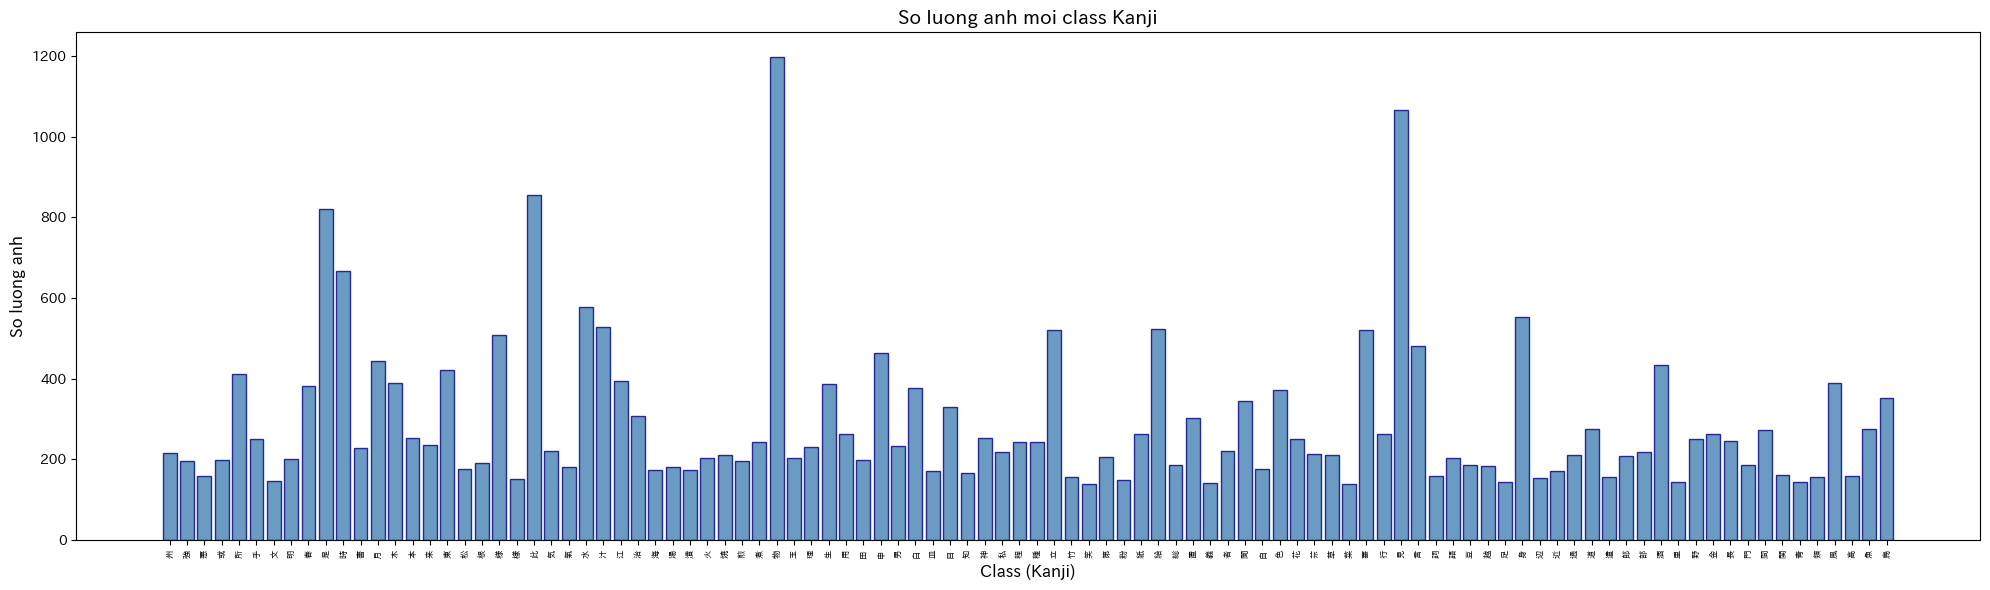

Min: 139 | Max: 1199 | TB: 293.6 ảnh/class


In [7]:
label_counts = Counter(labels)
counts = [label_counts[i] for i in range(len(class_names))]

plt.figure(figsize=(20, 6))
plt.bar(range(len(class_names)), counts, color='steelblue', edgecolor='navy', alpha=0.8)
plt.xlabel('Class (Kanji)', fontsize=12)
plt.ylabel('So luong anh', fontsize=12)
plt.title('So luong anh moi class Kanji', fontsize=14, fontweight='bold')
plt.xticks(range(len(class_names)), kanji_chars, fontsize=6, rotation=90)
plt.tight_layout()
plt.show()

print(f"Min: {min(counts)} | Max: {max(counts)} | TB: {np.mean(counts):.1f} ảnh/class")

### 5.3 Hiển thị 10 ảnh ngẫu nhiên

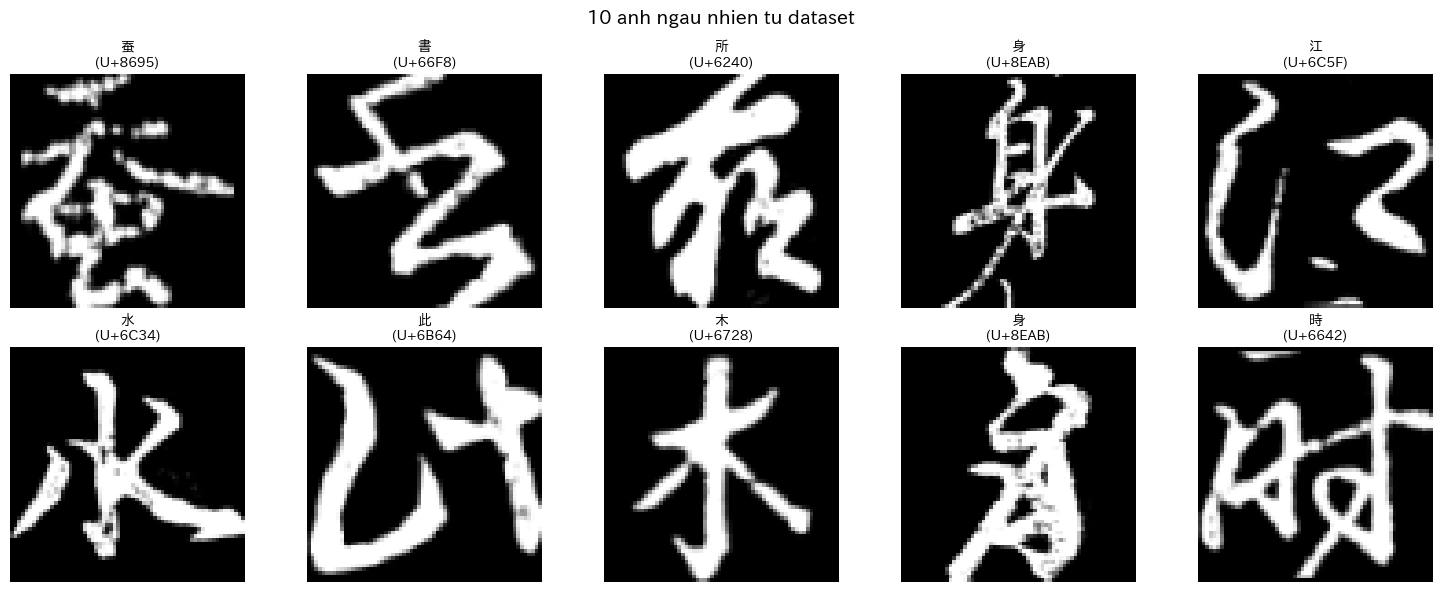

In [8]:
random_indices = random.sample(range(len(images)), 10)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle('10 anh ngau nhien tu dataset', fontsize=14, fontweight='bold')
for i, idx in enumerate(random_indices):
    ax = axes[i // 5, i % 5]
    ax.imshow(images[idx][:, :, 0], cmap='gray')
    ax.set_title(f'{unicode_to_kanji(class_names[labels[idx]])}\n({class_names[labels[idx]]})', fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 6. Chia dữ liệu

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    images, labels, test_size=0.3, random_state=SEED, stratify=labels)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

y_train_cat = keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_cat = keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_cat = keras.utils.to_categorical(y_test, NUM_CLASSES)

print(f"Train: {len(X_train)} ({len(X_train)/len(images)*100:.1f}%)")
print(f"Val:   {len(X_val)} ({len(X_val)/len(images)*100:.1f}%)")
print(f"Test:  {len(X_test)} ({len(X_test)/len(images)*100:.1f}%)")

Train: 20555 (70.0%)
Val:   4405 (15.0%)
Test:  4405 (15.0%)


## 7. Data Augmentation (tf.data)

In [10]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(factor=10/360, fill_mode='nearest'),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1, fill_mode='nearest'),
    layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='nearest'),
], name='data_augmentation')

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train_cat))
train_ds = train_ds.shuffle(len(X_train), seed=SEED).batch(BATCH_SIZE)
train_ds = train_ds.map(lambda x,y: (data_augmentation(x, training=True), y),
                        num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val_cat)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test_cat)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print(f"✅ Pipeline: Train={len(train_ds)} batches, Val={len(val_ds)}, Test={len(test_ds)}")

✅ Pipeline: Train=643 batches, Val=138, Test=138


## 8. ResNet18 (Custom Implementation)

In [11]:

# ==============================
# Residual Block
# ==============================
def residual_block(x, filters, stride=1):
    shortcut = x

    # Conv 1
    x = layers.Conv2D(filters, (3,3), strides=stride, padding='same',
                      use_bias=False, kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # Conv 2
    x = layers.Conv2D(filters, (3,3), strides=1, padding='same',
                      use_bias=False, kernel_initializer='he_normal')(x)
    x = layers.BatchNormalization()(x)

    # Shortcut
    if stride != 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1,1), strides=stride,
                                 use_bias=False, kernel_initializer='he_normal')(shortcut)
        shortcut = layers.BatchNormalization()(shortcut)

    # Add
    x = layers.Add()([x, shortcut])
    x = layers.Activation('relu')(x)

    return x


# ==============================
# ResNet18
# ==============================
def build_resnet18(input_shape=(64,64,3), num_classes=100):
    inputs = layers.Input(shape=input_shape)

    # 🔥 Stem (GIỮ NHẸ)
    x = layers.Conv2D(64, (3,3), strides=1, padding='same',
                      use_bias=False, kernel_initializer='he_normal')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)

    # ==============================
    # Stage 1 (64)
    # ==============================
    x = residual_block(x, 64, stride=1)
    x = residual_block(x, 64, stride=1)

    # ==============================
    # Stage 2 (128)
    # ==============================
    x = residual_block(x, 128, stride=2)
    x = residual_block(x, 128, stride=1)

    # ==============================
    # Stage 3 (256)
    # ==============================
    x = residual_block(x, 256, stride=2)
    x = residual_block(x, 256, stride=1)

    # ==============================
    # Stage 4 (512)
    # ==============================
    x = residual_block(x, 512, stride=2)
    x = residual_block(x, 512, stride=1)

    # ==============================
    # Head
    # ==============================
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs, name='ResNet18_Kanji')

    return model

model = build_resnet18(IMG_SHAPE, NUM_CLASSES)
model.summary()

Model: "ResNet18_Kanji"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 64, 64, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 64, 64,    │      1,728 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 64, 64,    │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │ activation[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 64, 64,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation_2[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │     36,864 │ activation_3[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 64, 64,    │          0 │ batch_normalizat

 Total params: 11,229,732 (42.84 MB)

 Trainable params: 11,220,132 (42.80 MB)

 Non-trainable params: 9,600 (37.50 KB)

## 9. Compile & Training

In [12]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy', metrics=['accuracy'])

callback_list = [
    callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]
print("✅ Compiled: Adam(lr=1e-3), categorical_crossentropy")

✅ Compiled: Adam(lr=1e-3), categorical_crossentropy


In [13]:
print("🚀 Training ResNet18...")
history = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds,
                    callbacks=callback_list, verbose=1)
print(f"\n✅ Done! Epochs: {len(history.history['loss'])}")

🚀 Training ResNet18...
Epoch 1/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 111s 132ms/step - accuracy: 0.4906 - loss: 2.1596 - val_accuracy: 0.7019 - val_loss: 1.1027 - learning_rate: 0.0010
Epoch 2/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 72s 112ms/step - accuracy: 0.8448 - loss: 0.5879 - val_accuracy: 0.8831 - val_loss: 0.4238 - learning_rate: 0.0010
Epoch 3/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 74s 115ms/step - accuracy: 0.9073 - loss: 0.3445 - val_accuracy: 0.9312 - val_loss: 0.2480 - learning_rate: 0.0010
Epoch 4/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 75s 116ms/step - accuracy: 0.9344 - loss: 0.2463 - val_accuracy: 0.9287 - val_loss: 0.2607 - learning_rate: 0.0010
Epoch 5/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 75s 116ms/step - accuracy: 0.9466 - loss: 0.1946 - val_accuracy: 0.9389 - val_loss: 0.2141 - learning_rate: 0.0010
Epoch 6/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 75s 117ms/step - accuracy: 0.9581 - loss: 0.1564 - val_accuracy: 0.9494 - val_loss: 0.1888 - learning_rate: 0.0010
Epoch 7/50
643/643 ━━━━━━━━━━━━━━━━━━━━ 75s 11

## 10. Phân tích kết quả
### 10.1 Learning Curves

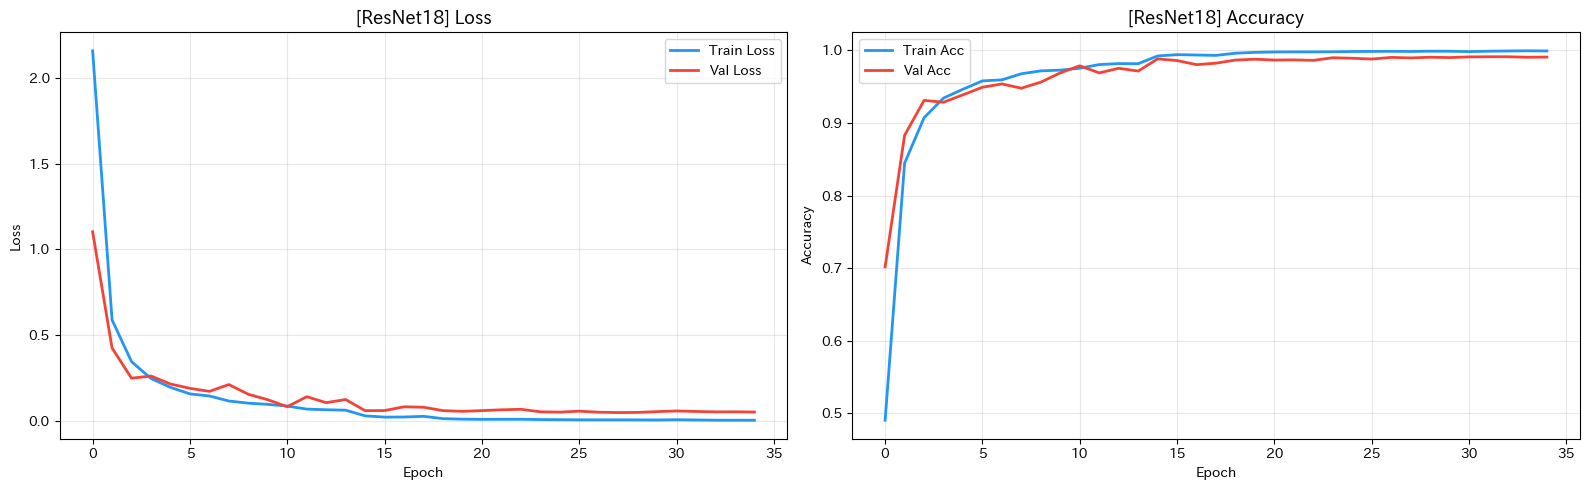

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(history.history['loss'], label='Train Loss', linewidth=2, color='#2196F3')
axes[0].plot(history.history['val_loss'], label='Val Loss', linewidth=2, color='#F44336')
axes[0].set_title('[ResNet18] Loss', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Train Acc', linewidth=2, color='#2196F3')
axes[1].plot(history.history['val_accuracy'], label='Val Acc', linewidth=2, color='#F44336')
axes[1].set_title('[ResNet18] Accuracy', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### 10.2 Test Evaluation

In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=1)
print(f"\n📊 Test Loss: {test_loss:.4f}  |  Test Accuracy: {test_accuracy*100:.2f}%")

138/138 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - accuracy: 0.9873 - loss: 0.0556

📊 Test Loss: 0.0556  |  Test Accuracy: 98.73%


### 10.3 Classification Report

In [16]:
y_pred = np.argmax(model.predict(X_test), axis=1)
print(classification_report(y_test, y_pred, target_names=kanji_chars, digits=4))

138/138 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step
              precision    recall  f1-score   support

           州     1.0000    0.9697    0.9846        33
           強     1.0000    1.0000    1.0000        30
           悪     1.0000    0.9583    0.9787        24
           或     1.0000    1.0000    1.0000        30
           所     0.9841    1.0000    0.9920        62
           手     0.9744    1.0000    0.9870        38
           文     0.9565    1.0000    0.9778        22
           明     1.0000    1.0000    1.0000        30
           春     1.0000    0.9825    0.9912        57
           是     1.0000    1.0000    1.0000       123
           時     0.9901    1.0000    0.9950       100
           書     0.9706    0.9706    0.9706        34
           月     1.0000    0.9545    0.9767        66
           木     1.0000    0.9828    0.9913        58
           本     0.9737    0.9737    0.9737        38
           来     1.0000    0.9714    0.9855        35
           東     1.0000    0.9841    0.

### 10.4 Confusion Matrix (Top 15)

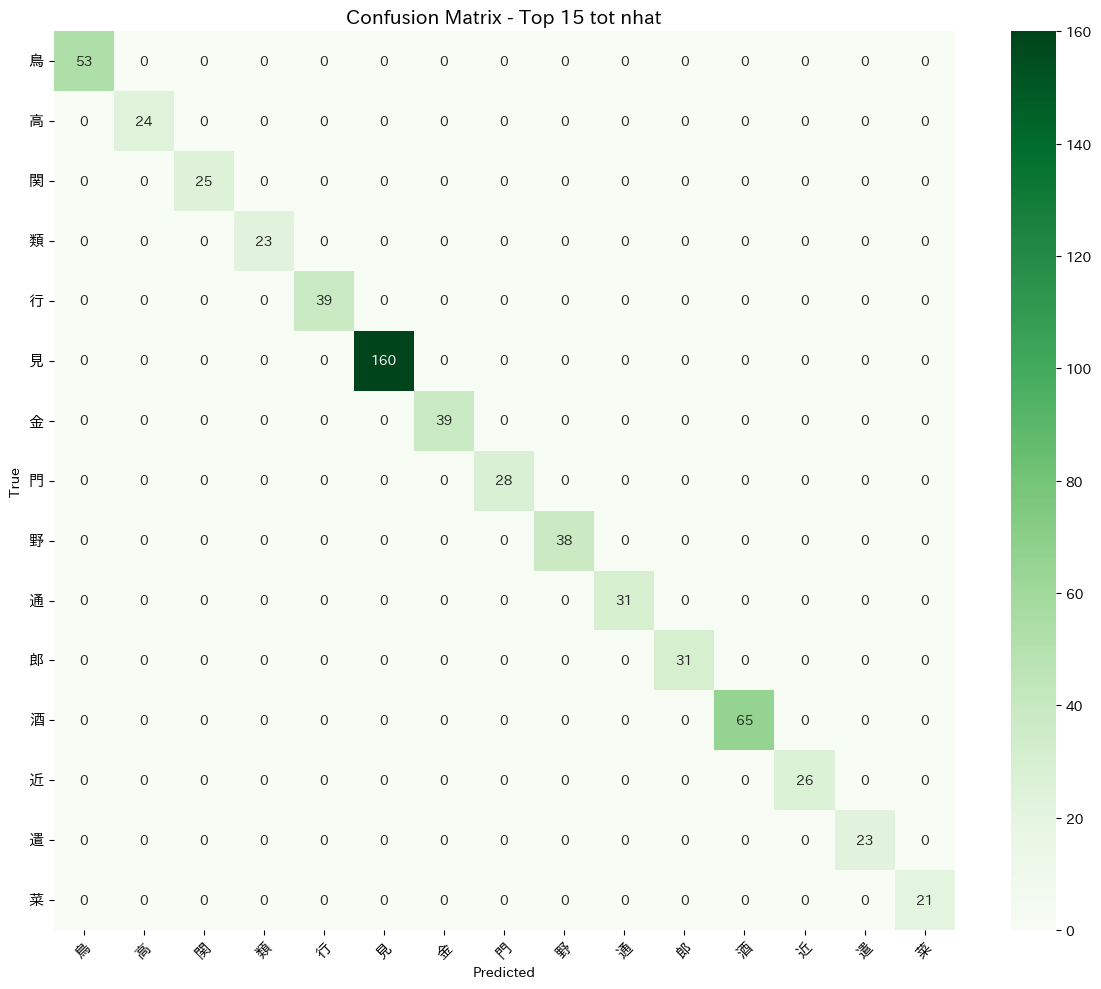


✅ Top 15 tốt nhất:
   鳥 (U+9CE5): 100.00%
   高 (U+9AD8): 100.00%
   関 (U+95A2): 100.00%
   類 (U+985E): 100.00%
   行 (U+884C): 100.00%
   見 (U+898B): 100.00%
   金 (U+91D1): 100.00%
   門 (U+9580): 100.00%
   野 (U+91CE): 100.00%
   通 (U+901A): 100.00%
   郎 (U+90CE): 100.00%
   酒 (U+9152): 100.00%
   近 (U+8FD1): 100.00%
   遣 (U+9063): 100.00%
   菜 (U+83DC): 100.00%


In [17]:
cm = confusion_matrix(y_test, y_pred)
class_total = cm.sum(axis=1)
class_accuracy = np.divide(cm.diagonal(), class_total,
                           out=np.zeros(len(class_total), dtype=float),
                           where=class_total != 0)

# Top 15 tốt nhất
best_idx = np.argsort(class_accuracy)[-15:][::-1]
plt.figure(figsize=(12, 10))
sns.heatmap(cm[np.ix_(best_idx, best_idx)], annot=True, fmt='d', cmap='Greens',
            xticklabels=[kanji_chars[i] for i in best_idx],
            yticklabels=[kanji_chars[i] for i in best_idx])
plt.title('Confusion Matrix - Top 15 tot nhat', fontsize=14, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(fontsize=11, rotation=45); plt.yticks(fontsize=11, rotation=0)
plt.tight_layout(); plt.show()

print("\n✅ Top 15 tốt nhất:")
for i in best_idx:
    print(f"   {kanji_chars[i]} ({class_names[i]}): {class_accuracy[i]*100:.2f}%")

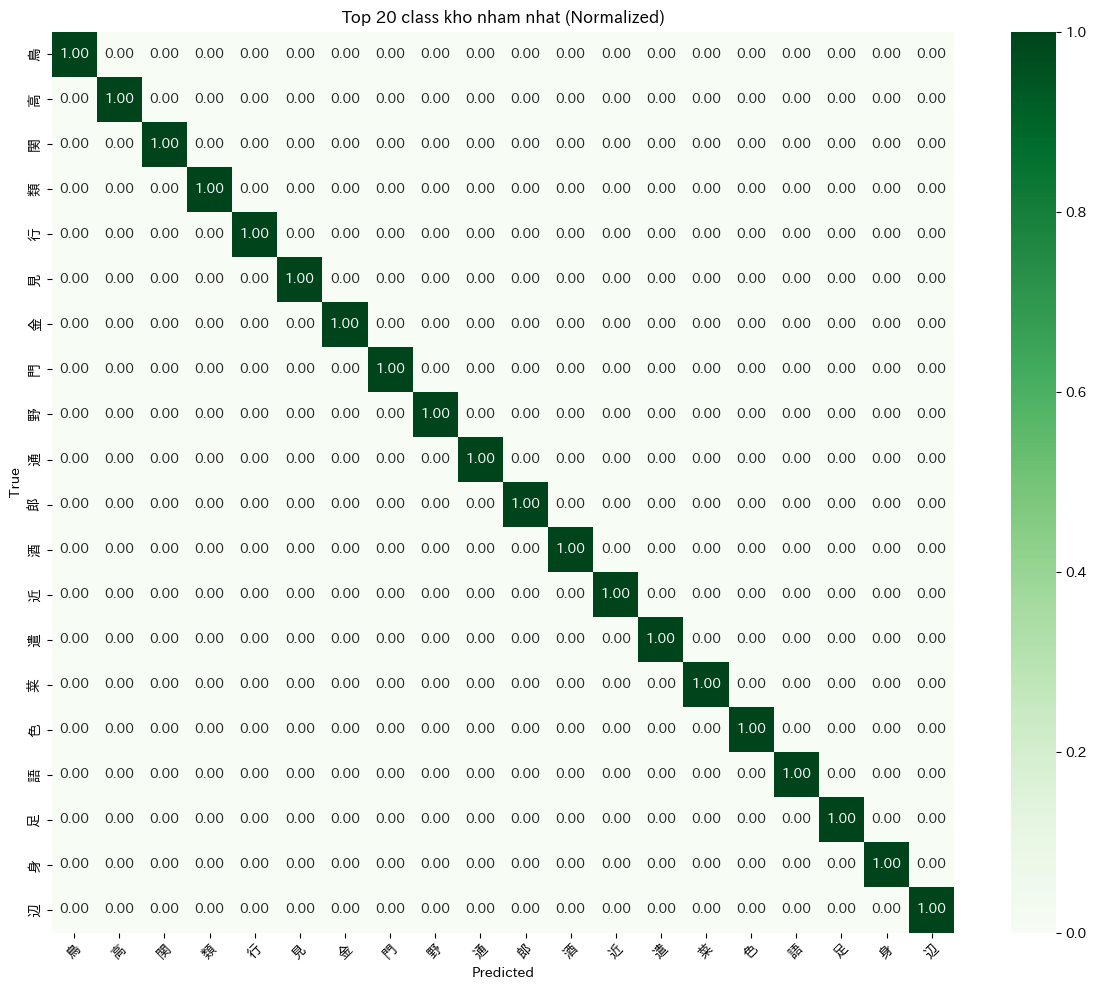

In [18]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# lấy top 20 class tốt nhất
class_accuracy = np.diag(cm_norm)
best_indices = np.argsort(class_accuracy)[-20:][::-1]

cm_best = cm_norm[np.ix_(best_indices, best_indices)]
labels_best = [kanji_chars[i] for i in best_indices]

plt.figure(figsize=(12, 10))
sns.heatmap(cm_best, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=labels_best, yticklabels=labels_best)

plt.title('Top 20 class kho nham nhat (Normalized)', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

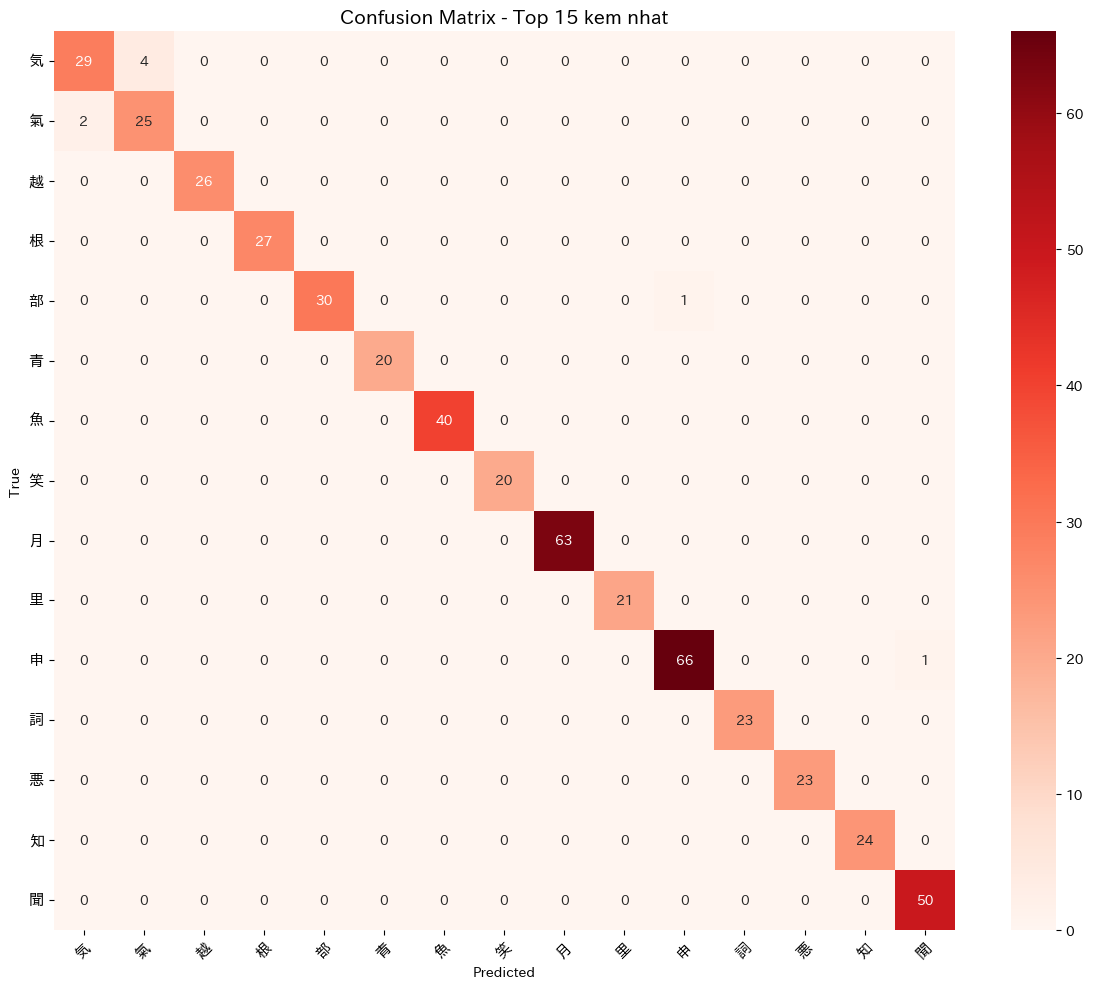


❌ Top 15 kém nhất:
   気 (U+6C17): 87.88%
   氣 (U+6C23): 92.59%
   越 (U+8D8A): 92.86%
   根 (U+6839): 93.10%
   部 (U+90E8): 93.75%
   青 (U+9752): 95.24%
   魚 (U+9B5A): 95.24%
   笑 (U+7B11): 95.24%
   月 (U+6708): 95.45%
   里 (U+91CC): 95.45%
   申 (U+7533): 95.65%
   詞 (U+8A5E): 95.83%
   悪 (U+60AA): 95.83%
   知 (U+77E5): 96.00%
   聞 (U+805E): 96.15%


In [19]:
# Top 15 kém nhất
worst_idx = np.argsort(class_accuracy)[:15]
plt.figure(figsize=(12, 10))
sns.heatmap(cm[np.ix_(worst_idx, worst_idx)], annot=True, fmt='d', cmap='Reds',
            xticklabels=[kanji_chars[i] for i in worst_idx],
            yticklabels=[kanji_chars[i] for i in worst_idx])
plt.title('Confusion Matrix - Top 15 kem nhat', fontsize=14, fontweight='bold')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(fontsize=11, rotation=45); plt.yticks(fontsize=11, rotation=0)
plt.tight_layout(); plt.show()

print("\n❌ Top 15 kém nhất:")
for i in worst_idx:
    print(f"   {kanji_chars[i]} ({class_names[i]}): {class_accuracy[i]*100:.2f}%")

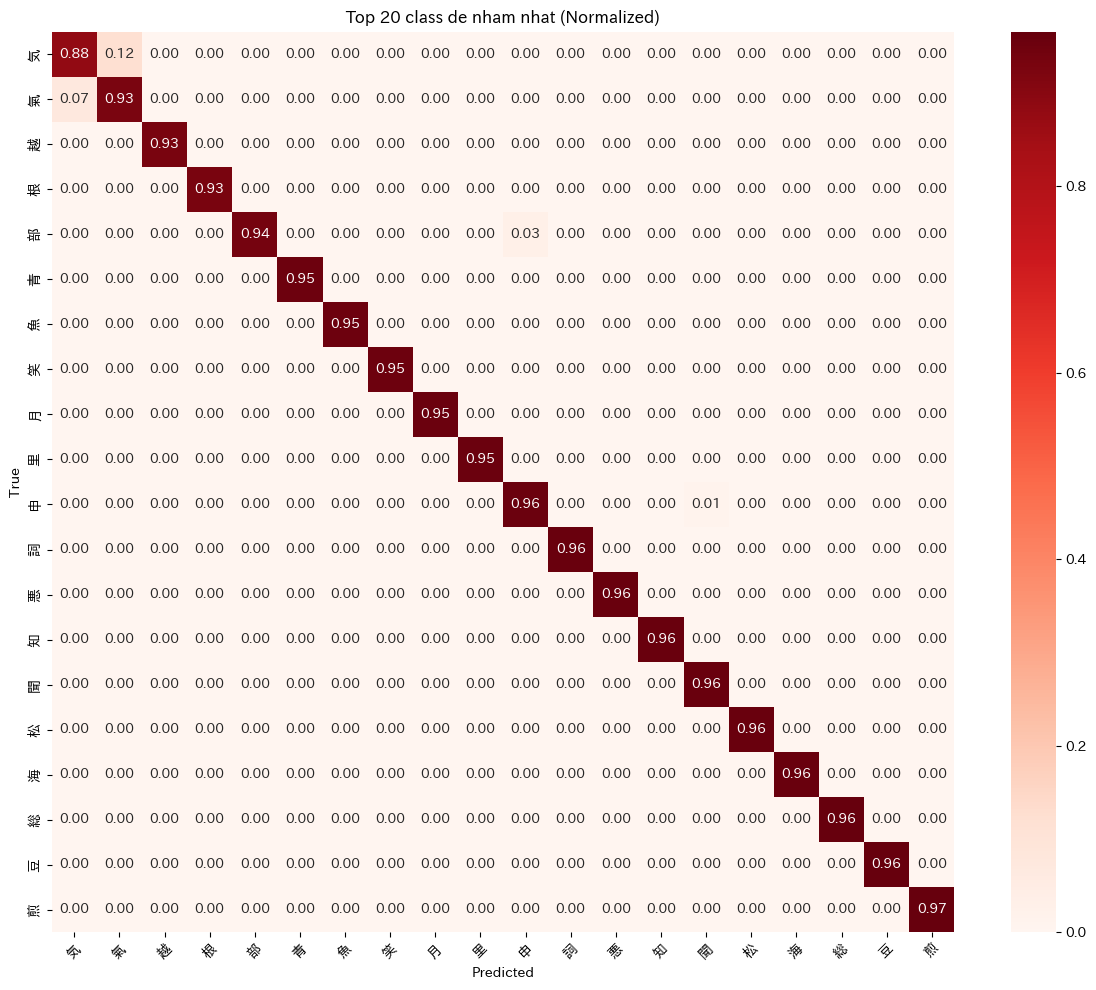

In [20]:
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# ❗ lấy 20 class có accuracy thấp nhất
class_accuracy = np.diag(cm_norm)
worst_indices = np.argsort(class_accuracy)[:20]

cm_worst = cm_norm[np.ix_(worst_indices, worst_indices)]
labels_worst = [kanji_chars[i] for i in worst_indices]

plt.figure(figsize=(12, 10))
sns.heatmap(cm_worst, annot=True, fmt='.2f', cmap='Reds',
            xticklabels=labels_worst, yticklabels=labels_worst)

plt.title('Top 20 class de nham nhat (Normalized)', fontweight='bold')
plt.xlabel('Predicted')
plt.ylabel('True')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 10.5 Tổng kết

In [21]:
correct = np.trace(cm); total = np.sum(cm)
print(f"Đúng: {correct}/{total} ({correct/total*100:.2f}%)")
print(f"Mean per-class acc: {np.mean(class_accuracy)*100:.2f}%")
print(f"Median per-class acc: {np.median(class_accuracy)*100:.2f}%")

Đúng: 4349/4405 (98.73%)
Mean per-class acc: 98.45%
Median per-class acc: 100.00%


## 11. Lưu Model & Labels

In [22]:
# ==================== LƯU MODEL ====================
save_path = os.path.join(SAVE_DIR, 'model_resnet18.h5')
model.save(save_path)
print(f"💾 Saved: {save_path} ({os.path.getsize(save_path)/(1024*1024):.2f} MB)")

# ==================== LƯU LABELS ====================
# Lưu mapping: index -> tên folder (U+XXXX) -> ký tự Kanji
# File này dùng cho demo sau này
label_data = {
    'class_names': class_names,          # ['U+4E00', 'U+4E8C', ...]
    'kanji_chars': kanji_chars,           # ['一', '二', ...]
    'num_classes': NUM_CLASSES,
    'img_size': IMG_SIZE,
    'input_shape': list(IMG_SHAPE),       # [64, 64, 3]
    'index_to_unicode': {str(i): class_names[i] for i in range(len(class_names))},
    'index_to_kanji': {str(i): kanji_chars[i] for i in range(len(kanji_chars))}
}

label_path = os.path.join(SAVE_DIR, 'labelsresnet18.json')
with open(label_path, 'w', encoding='utf-8') as f:
    json.dump(label_data, f, ensure_ascii=False, indent=2)

print(f"\n🏷️ Labels đã lưu: {label_path}")
print(f"   Số class: {len(class_names)}")
print(f"   Ví dụ: index 0 -> {class_names[0]} -> {kanji_chars[0]}")
print(f"   Ví dụ: index 1 -> {class_names[1]} -> {kanji_chars[1]}")

💾 Saved: /content/drive/MyDrive/dataset/model_resnet18.h5 (128.71 MB)

🏷️ Labels đã lưu: /content/drive/MyDrive/dataset/labelsresnet18.json
   Số class: 100
   Ví dụ: index 0 -> U+5DDE -> 州
   Ví dụ: index 1 -> U+5F37 -> 強


## 12. Tổng kết

In [23]:
print("=" * 60)
print("TỔNG KẾT - RESNET18")
print("=" * 60)
print(f"   Model:          ResNet18 (custom, 18 layers)")
print(f"   Input shape:    {IMG_SHAPE}")
print(f"   Num classes:    {NUM_CLASSES}")
print(f"   Total params:   {model.count_params():,}")
print(f"   Epochs trained: {len(history.history['loss'])}")
print(f"   Test Loss:      {test_loss:.4f}")
print(f"   Test Accuracy:  {test_accuracy*100:.2f}%")
print(f"   Model saved:    {save_path}")
print(f"   Labels saved:   {label_path}")
print("=" * 60)

TỔNG KẾT - RESNET18
   Model:          ResNet18 (custom, 18 layers)
   Input shape:    (64, 64, 3)
   Num classes:    100
   Total params:   11,229,732
   Epochs trained: 35
   Test Loss:      0.0556
   Test Accuracy:  98.73%
   Model saved:    /content/drive/MyDrive/dataset/model_resnet18.h5
   Labels saved:   /content/drive/MyDrive/dataset/labelsresnet18.json
